# 21 — El jerárquico por tipo de consulta: llevar cada contexto a la parte donde actúa

## Por qué

Los cuadernos 17, 19 y 20 repiten lo mismo. El clima, las enfermedades de la ciudad y El Niño **sí mueven
algo**: la IRA de la ciudad un 6-7 %, la diarrea un 16 %. Pero al **triage total** llegan diluidos, en un 1-3 %.
`CLAUDE.md` lo anticipaba: si lo respiratorio es el 10 % del total y sube un 30 %, el total sube un 3 %,
invisible bajo un ruido del 10-12 %.

**La salida es no mirar el total sino sus partes**, y darle a cada parte el contexto que le toca.

## Qué particiones existen (fila `jerarquico_tipo` de `variables.csv`)

| Partición | Cobertura | Fuente |
|---|---|---|
| **Bandas de edad** (0-4, 5-14, 15-44, 45-64, 65+) | 100 %, desde 2020 | `triage_edad.parquet` |
| **Obstétrico frente al resto** | 100 %, desde 2020 | `triage_nivel.parquet` (niveles -G) |
| Diagnósticos | **41 %** (son ingresos) | `perfil_dx_diario` |
| Motivo de consulta (NLP) | 2025-2026, sin procesar | `NLP/` |

**El cruce edad × obstétrico no existe todavía.** Haría falta una extracción agregada nueva, que solo puede
hacer el propietario.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from matplotlib import pyplot as plt
import indices as ix
import desenlace as de
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
dias = pd.date_range("2020-01-01", "2026-09-20")
ed = pd.read_parquet(RAIZ / "salidas/triage_edad.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
E = ed.pivot_table(index="dia", columns="banda", values="n", aggfunc="sum").reindex(dias).fillna(0)
nv = pd.read_parquet(RAIZ / "salidas/triage_nivel.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
obst = nv[nv.nivel.str.endswith("-G")].groupby("dia").n.sum().reindex(dias).fillna(0)
tot = nv.groupby("dia").n.sum().reindex(dias).fillna(0)
P = pd.DataFrame({"edad 0-4": E["0-4"], "edad 5-14": E["5-14"], "edad 15-44": E["15-44"], "edad 45-64": E["45-64"], "edad 65+": E["65-+"],
                  "obstétrico": obst, "no obstétrico": tot - obst, "TOTAL": tot})
P.loc["2024-03-19":"2024-03-21"] = np.nan
peso = (P.loc["2022":"2024"].mean() / P.loc["2022":"2024", "TOTAL"].mean() * 100).round(1)
print("Peso de cada parte en 2022-2024 (%):"); peso.drop("TOTAL")

Peso de cada parte en 2022-2024 (%):


edad 0-4          3.0
edad 5-14         4.4
edad 15-44       55.3
edad 45-64       18.4
edad 65+         18.8
obstétrico       11.5
no obstétrico    88.5
dtype: float64

---
# 1. Cada parte tiene su propia estación

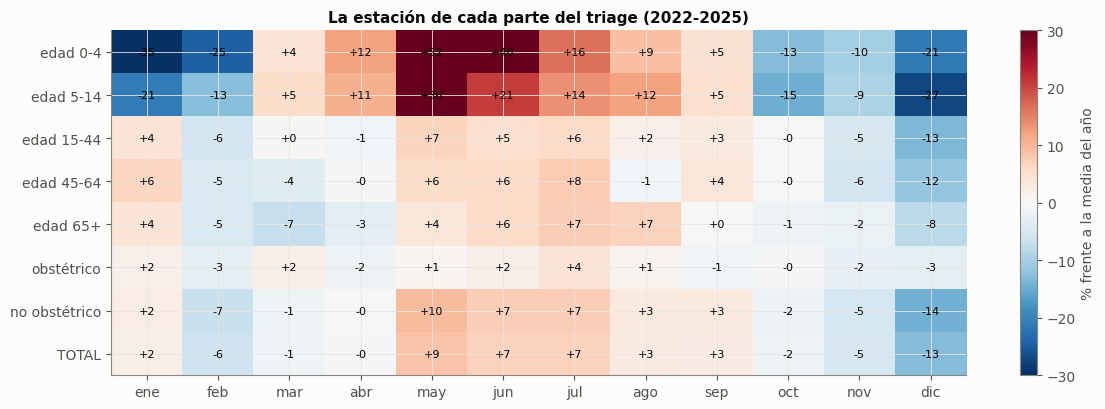

,amplitud de la estación (puntos %)
edad 0-4,86.8
edad 5-14,63.6
edad 15-44,20.1
edad 45-64,19.3
edad 65+,15.3
obstétrico,7.2
no obstétrico,24.0
TOTAL,21.6


In [2]:
x = np.log(P.loc["2022":"2025"].resample("MS").mean())
forma = (np.exp((x - x.groupby(x.index.year).transform("mean")).groupby(x.index.month).mean()) - 1) * 100
fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(forma.T.values, cmap="RdBu_r", vmin=-30, vmax=30, aspect="auto")
ax.set_xticks(range(12), MESES); ax.set_yticks(range(forma.shape[1]), forma.columns)
for (i, j), v in np.ndenumerate(forma.T.values): ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="% frente a la media del año"); ax.set_title("La estación de cada parte del triage (2022-2025)")
plt.tight_layout(); plt.show()
amp = (forma.max() - forma.min()).round(1).rename("amplitud de la estación (puntos %)"); amp.to_frame()

**Lectura. Las partes tienen estaciones muy distintas.**

- **0-4 años: 87 puntos de amplitud.** **5-14: 64.** Es la temporada respiratoria y escolar, y es la estacionalidad más fuerte del hospital.
- **Los adultos (15-64) y los mayores** se mueven entre 15 y 20 puntos.
- **Lo obstétrico casi no tiene estación** (7 puntos).
- **En el total (22 puntos) las estaciones de las partes se mezclan y se cancelan.** La fuerte estación pediátrica pesa poco porque los niños son solo el 7 % del triage.

---
# 2. El contexto externo, parte por parte (2022-03 a 2024-12)

Cada parte se lleva a su residuo semanal: sin calendario, sin el nivel del año y sin los escalones de la red,
igual que `desenlace.py`, conservando la estación. Contra cada parte se barren:
- las 6 familias de enfermedad, con rezago de 0 a 2 semanas;
- los 7 índices de clima y 2 rachas, con rezago de 0 a 4;
- El Niño y La Niña.

En total son 77 pruebas por parte, con mes fijo, errores HAC y BH por parte.

In [3]:
cal = (pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha")
         .reindex(dias)[de.CAL].apply(pd.to_numeric, errors="coerce").fillna(0))
completas = de._semana(P["TOTAL"].notna().astype(int)) == 7
cal_w = de._semana(cal).loc[de.INICIO:"2024-12-29"]
RESID = {}
for c in P:
    w = de._semana(P[c]).where(completas).loc[de.INICIO:"2024-12-29"]
    RESID[c] = de._residuo(w, cal_w)
RESID = pd.DataFrame(RESID)
FAM = ix.familias_enfermedad(); IC = ix.indices_clima()
REG = ix.regimenes_diarios()[["el_nino", "la_nina"]].resample("W-SAT").mean(); REG.index -= pd.Timedelta(days=6)
X = {}
for f in FAM:
    for L in range(3): X[f"{f} (−{L} sem)"] = FAM[f].shift(L)
for c in IC:
    for L in range(5): X[f"{c} (−{L} sem)"] = IC[c].shift(L)
for c in REG: X[c] = REG[c]
X = pd.DataFrame(X)
def barrido(y):
    idx = y.dropna().index; filas = []
    mes = pd.get_dummies(pd.Index(idx.month), prefix="m", drop_first=True).set_index(idx).astype(float)
    for c in X:
        xs = (X[c] - X[c].loc[:"2024"].mean()) / X[c].loc[:"2024"].std()
        D = pd.concat([y.rename("y"), xs.rename("x"), mes], axis=1).loc[idx].dropna()
        if len(D) < 60 or D.x.std() == 0: continue
        r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
        filas.append({"variable": c, "efecto %": 100 * (np.exp(r.params["x"]) - 1), "p": r.pvalues["x"]})
    T = pd.DataFrame(filas); T["q"] = multipletests(T.p, method="fdr_bh")[1]; return T
RB = {c: barrido(RESID[c]) for c in RESID}
res = pd.DataFrame({c: {"pruebas": len(T), "p < 0,05": int((T.p < .05).sum()), "sobreviven BH": int((T.q < .10).sum()),
                        "mayor efecto que sobrevive %": round(T.loc[T.q < .10, "efecto %"].abs().max(), 1) if (T.q < .10).any() else np.nan,
                        "ruido semanal (desv. del residuo) %": round(100 * RESID[c].std(), 1)} for c, T in RB.items()}).T
res

,pruebas,"p < 0,05",sobreviven BH,mayor efecto que sobrevive %,ruido semanal (desv. del residuo) %
edad 0-4,65.0,10.0,1.0,7.7,26.0
edad 5-14,65.0,10.0,1.0,6.9,23.0
edad 15-44,65.0,15.0,12.0,3.5,6.6
edad 45-64,65.0,16.0,11.0,3.1,8.5
edad 65+,65.0,11.0,7.0,4.6,9.1
obstétrico,65.0,10.0,1.0,3.5,9.7
no obstétrico,65.0,13.0,11.0,2.1,6.4
TOTAL,65.0,15.0,11.0,2.1,6.0


**Lectura.**

- **En las partes, el contexto actúa con efectos hasta 3 veces mayores que en el total.** El mayor efecto que sobrevive es de 7,7 % en 0-4 años, 6,9 % en 5-14 y 4,6 % en 65+, contra 2,1 % en el total.
- **Pero las partes pequeñas son muy ruidosas.** El residuo semanal de 0-4 años varía un 26 % y el de 5-14 un 23 %, porque son ~15-25 triages por semana. **Por eso, con efectos más grandes, sobreviven menos pruebas** (1 en cada banda pediátrica).
- **Las partes grandes ganan en número:** 15-44 (12 pruebas que sobreviven), 45-64 (11) y 65+ (7). **Sumadas, 32 contra 11 del total.**
- **La partición por edad gana a la obstétrica:** en lo obstétrico sobrevive 1 prueba y en lo no obstétrico 11, igual que en el total.
- Según la regla preregistrada, **al cuaderno 22 va la partición por bandas de edad.**

In [4]:
filas = []
for c, T in RB.items():
    for _, r in T[T.q < .10].sort_values("p").head(6).iterrows():
        filas.append({"parte": c, "variable": r.variable, "efecto %": round(r["efecto %"], 2), "q": round(r.q, 3)})
pd.DataFrame(filas) if filas else "nada sobrevive"

,parte,variable,efecto %,q
0,edad 0-4,dias_desde_semana_muy_lluviosa (−0 sem),7.75,0.016
1,edad 5-14,el_nino,-6.92,0.006
2,edad 15-44,racha_seca (−3 sem),2.79,0.002
3,edad 15-44,estado_1 (−0 sem),1.74,0.004
4,edad 15-44,digestiva (−0 sem),3.46,0.004
5,edad 15-44,digestiva (−1 sem),2.51,0.007
6,edad 15-44,racha_seca (−4 sem),1.91,0.008
7,edad 15-44,el_nino,1.82,0.012
8,edad 45-64,racha_seca (−3 sem),2.80,0.033
9,edad 45-64,el_nino,2.07,0.033


**Lectura. Cada parte tiene su contexto:**

- **Mayores de 65: la lluvia reciente.** Cuanto más cerca está la última semana muy lluviosa, más triage de mayores, hasta **+4,6 %** a 1-4 semanas, con q < 0,001. Encaja con las caídas en la calle y la descompensación respiratoria y cardíaca con el frío húmedo.
- **Adultos (15-64): las rachas secas largas** (+2,3 a +2,8 % a 2-4 semanas), **la diarrea de la ciudad** (+3,5 %, la misma semana) y **El Niño** (+1,8 a +2,1 %).
- **0-4 años: el clima de la semana** (+7,7 %). **5-14: El Niño** (−6,9 %): menos triage escolar en el año seco.
- **Lo que mueve a los mayores no es lo que mueve a los niños ni a los adultos.** En el total esas señales se diluyen o se cancelan. Es justo el argumento del modelo jerárquico.

---
# 3. Lo que deja este cuaderno

**Lo que deja este cuaderno:**

1. **El triage se puede repartir completo desde 2020** por edad (5 bandas) o por obstétrico. Los diagnósticos no sirven (41 %, son ingresos).
2. **En las partes, el contexto actúa hasta 3 veces más fuerte** que en el total, y **cada parte responde a cosas distintas:** mayores a la lluvia reciente, adultos a las rachas secas, la diarrea y El Niño, niños al clima de la semana.
3. **El costo es el ruido.** Las bandas pediátricas tienen 15-25 triages por semana y un ruido del 23-26 %.
4. **Para el cuaderno 22:** jerárquico por **bandas de edad**, con el contexto de cada familia en su banda, y el total como suma.

**Pendiente del propietario:** una extracción agregada de **edad × obstétrico × día** (o, mejor, **edad × motivo**, cuando el NLP procese el corpus) afinaría la partición. El motivo de consulta es el desenlace específico que pide `CLAUDE.md`.